# Честный выбор: какой прогноз оставить

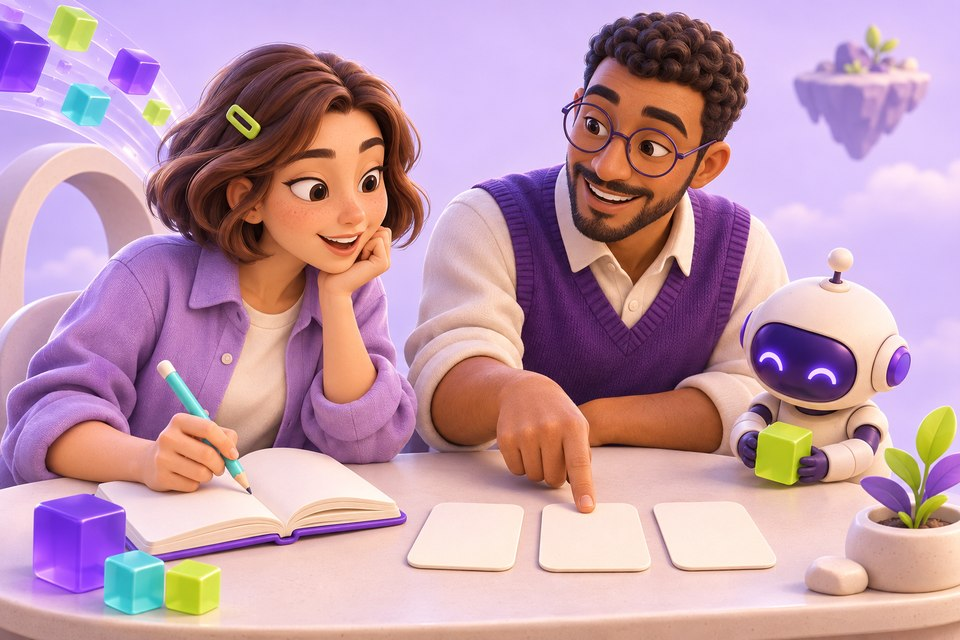

**Выберем правило на одной части ряда и проверим на другой.**

**Твой результат:** Разделить выбор модели и окончательную проверку.

**Что разбираем:** Короткое сравнение правил прогноза вместо многослойных сетей SP500 из архива.

**Данные:** Выдуманный ряд с трендом и волной.

**Перед началом:**

- Запускать ячейки сверху вниз
- Читать списки и простые выражения Python

**Рядом с тобой:** Мира — ученица, Данил — человек-ментор, Пикс — бот-помощник. Это вымышленные персонажи: их реплики объясняют шаги и не проверяют код автоматически.

## Три шага

1. Разделим время на три части
2. Сравним два понятных правила
3. Откроем отложенный участок

Затем — твой небольшой эксперимент. Проходи ячейки сверху вниз.

## Подготовь рабочее место

Запускай код сверху вниз: сначала эту подготовку, затем три шага. Проверки `assert` останавливают выполнение, если результат не совпал с условием.

Библиотеки для урока: **numpy, matplotlib**.

In [1]:
%matplotlib inline
import matplotlib as mpl
mpl.rcParams.update({
    'figure.figsize': (7, 3.5), 'figure.dpi': 100,
    'figure.facecolor': '#fffdf8', 'axes.facecolor': '#fffdf8',
    'font.family': 'DejaVu Sans', 'font.size': 10,
    'axes.titlesize': 12, 'axes.labelcolor': '#302c3f',
    'text.color': '#302c3f', 'savefig.bbox': 'tight',
})
import numpy as np
import matplotlib.pyplot as plt


<a id="step-1"></a>

## 1. Разделим время на три части

Первые точки — история, следующие — выбор правила. Последние точки оставим для единственной итоговой проверки.

In [2]:
t = np.arange(120)
series = 10 + 0.08*t + np.sin(t/4)
ids = np.arange(5, len(series))
X = np.array([series[i-5:i] for i in ids])
y = series[ids]
train = ids < 70
validation = (ids >= 70) & (ids < 95)
test = ids >= 95
assert not np.any(train & validation | train & test | validation & test)
print('История / выбор / проверка:', train.sum(), validation.sum(), test.sum())


История / выбор / проверка: 65 25 25


**Что проверить:** Три непересекающихся диапазона времени.

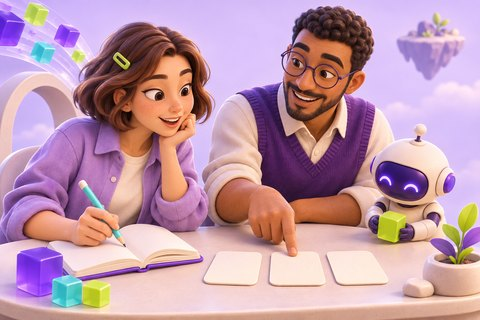

> **Мира:** Почему нельзя выбрать по последним точкам?

> **Данил:** Их тогда уже нельзя считать новой проверкой. Для выбора выделим отдельный участок.

> **Пикс:** Убедись, что маски диапазонов не пересекаются.

<a id="step-2"></a>

## 2. Сравним два понятных правила

Первое повторяет последнее значение. Второе продолжает последний шаг; оба используют только прошлое.

In [3]:
rules = {
    'Повтор': lambda windows: windows[:, -1],
    'Продолжение шага': lambda windows: 2*windows[:, -1] - windows[:, -2],
}
scores = {name: np.mean(np.abs(rule(X[validation])-y[validation]))
          for name, rule in rules.items()}
chosen = min(scores, key=scores.get)
assert chosen in rules
for name, error in scores.items():
    print(f'{name}: MAE выбора = {error:.3f}')
print('Оставляем:', chosen)


Повтор: MAE выбора = 0.168
Продолжение шага: MAE выбора = 0.039
Оставляем: Продолжение шага


**Что проверить:** Имя правила выбирается из существующего словаря по рассчитанной MAE.

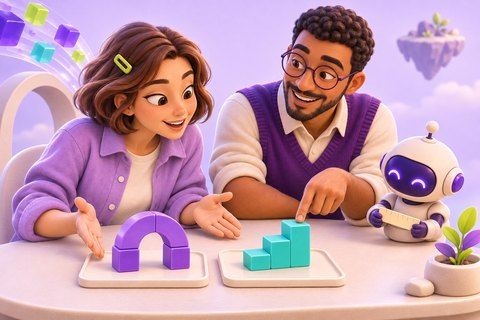

> **Мира:** Это вообще модели, если мы ничего не обучали?

> **Данил:** Это базовые правила прогноза. Они полезны до обучения сложной сети.

> **Пикс:** Имя выбранного правила должно быть ключом rules.

<a id="step-3"></a>

## 3. Откроем отложенный участок

Теперь применим выбранное правило к последнему участку. Его ошибку не используем для смены победителя.

Итоговая MAE: 0.039; правило: Продолжение шага


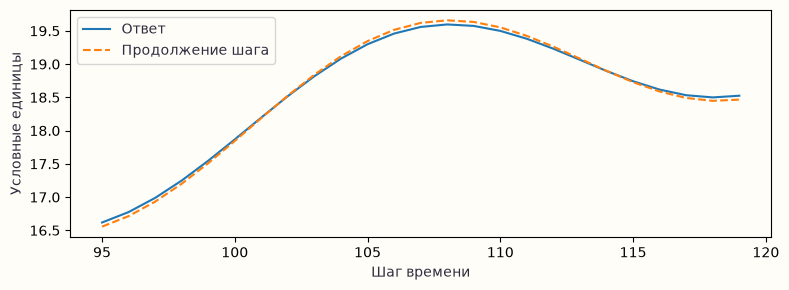

In [4]:
prediction = rules[chosen](X[test])
error = np.mean(np.abs(prediction-y[test]))
assert len(prediction) == test.sum()
print(f'Итоговая MAE: {error:.3f}; правило: {chosen}')
plt.figure(figsize=(8, 3))
plt.plot(ids[test], y[test], label='Ответ')
plt.plot(ids[test], prediction, '--', label=chosen)
plt.xlabel('Шаг времени')
plt.ylabel('Условные единицы')
plt.legend()
plt.tight_layout()
plt.show()


**Что проверить:** Итоговая ошибка и непустой график последнего участка.

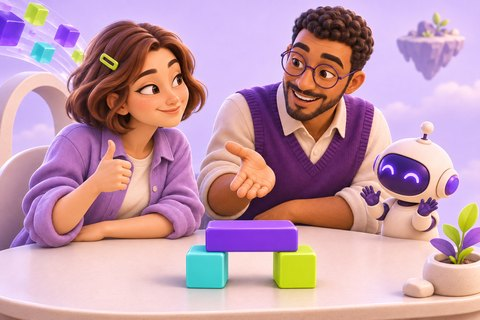

> **Мира:** А если здесь победило бы другое правило?

> **Данил:** Запишем результат. Подбирать заново по этой проверке нельзя без новой независимой проверки.

> **Пикс:** График строится по реальным значениям, без среза несуществующих эпох.

<a id="your-experiment"></a>

## Попробуй сам

Измени волну с sin(t/4) на sin(t/2).

**Где изменить:** series в шаге 1.

**Как проверить:** Снова получишь выбор и отдельную итоговую MAE, без обещания победителя.

## Что теперь умеешь

- Правила можно сравнить до сложного обучения.
- Выбор и итоговая проверка — разные данные.

## Границы этого примера

- Синтетический ряд не подтверждает работу на SP500.
- Окна итоговой части используют уже наблюдавшиеся прошлые точки: это прогноз по одному шагу.

## Продолжить глубже

[Полная исходная работа в неизменяемом архиве](<https://github.com/safal207/students/blob/2e46691c24aabcb6e71852e07254a0965fc3a59b/Stock/SP500_%22%D0%A1%D0%B0%D1%84%D0%BE%D0%BD%D0%BE%D0%B2_%D0%92%D1%80%D0%B5%D0%BC%D0%B5%D0%BD%D0%BD%D1%8B%D0%B5_%D1%80%D1%8F%D0%B4%D1%8B.ipynb>). Она сохраняет большой эксперимент и его авторские материалы; её требования могут отличаться от этого короткого урока.

**Источники исходной работы:**

- [Источник 1](<https://colab.research.google.com/github/safal207/hello-world/blob/master/SP500_%22%D0%A1%D0%B0%D1%84%D0%BE%D0%BD%D0%BE%D0%B2_%D0%92%D1%80%D0%B5%D0%BC%D0%B5%D0%BD%D0%BD%D1%8B%D0%B5_%D1%80%D1%8F%D0%B4%D1%8B.ipynb>)

<details>
<summary>Что исправлено и упрощено в уроке</summary>

**Ошибка · исходная ячейка 18 (от 0).** Оценка ссылается на неопределённую модель. → Выбор обращается к существующему ключу rules.

Проверка: assert chosen in rules

Фрагмент исходника: <code>currModel = modelX; построена modelX3</code>

---

**Ошибка · исходная ячейка 17 (от 0).** История четырёх эпох обрезана начиная с десятой: график пуст. → Показываются все точки итогового прогноза, неподходящий график обучения убран.

Проверка: len(prediction) == test.sum()

Фрагмент исходника: <code>epochs=4 и history.history[loss][10:]</code>

</details>